# Supplementary figure: INT deflections against matched rest controls

A task INT is read off a GLM residual and a rest INT is not, so a raw task-vs-rest contrast confounds the
condition with its processing. Here every task condition of HCP-YA 3T and HCP-D is contrasted with its
**matched rest control** (`restctrl`: rest put through the identical design projection, see
`timescales_process.ipynb`), so the only remaining difference is the task itself. Top row: the median
deflection per parcel; bottom row: the mean deflection per subject, tested against zero (Wilcoxon, BH-FDR).
The last cell compares the controlled deflection with the uncontrolled drop.

**Inputs:** `timescales_process.ipynb` for HCP-YA 3T and HCP-D (unfiltered arm, with `BUILD_REST_CONTROLS`).

In [1]:
import os
import warnings

warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import scipy as sp
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline

from statsmodels.stats.multitest import multipletests

from src.plotting import (plot_repeated_measures_violins, setup_notebook_style,
                          figure_scratch_dir, register_custom_colormaps)
from src.data import project_root
from src.supporting_data import load_supporting_data
from src.timescales import Timescales, TASK_RUN_GROUPS, MOVIE_GROUP
from snaplab_tools.plotting.utils import save_panel
from snaplab_tools.stats import significance_stars

setup_notebook_style()
# This notebook reads the cache directly, so it registers the S-A colormap itself (fig1_super gets it from
# load_notebook_data).
register_custom_colormaps()

{'snap_navy_gold': <matplotlib.colors.LinearSegmentedColormap at 0x776c2800a850>,
 'snap_indigo_gold': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f47b10>,
 'snap_purple_orange': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f47f90>,
 'snap_sydnor_sa': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f5c550>,
 'snap_blue_orange': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f5ca90>,
 'snap_blue_vermillion': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f5d010>,
 'snap_blue_red': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f5d510>,
 'snap_blue_brown': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f5dad0>,
 'snap_blue_pink': <matplotlib.colors.LinearSegmentedColormap at 0x776c20f5e110>}

In [2]:
# ── Configuration ───────────────────────────────────────────────────────────────────────────
RC_BASE = 'timescale_auc_zero_crossing'      # the primary estimator, unfiltered
RC_BRAIN_MAP = 'SA_Axis'
RC_N_REGIONS = 400

# Cache variants, each read with an explicit output_type (no INT is computed here): 'raw' for the last table's
# uncontrolled comparison only, 'ctrl' the matched rest control and 'resid' the task residual.
RC_VARIANTS = {'raw': '', 'ctrl': '_restctrl', 'resid': '_resids'}

# One block per figure column, with HCP-YA on its 3T registry (all 966 subjects, not fig1_super's 163).
RC_BLOCKS = [
    dict(id='HCP-YA', dataset='HCP-YA', modality='MRI3T',
         registry='scan_registry_HCP-YA.csv', title='HCP-YA 3T'),
    dict(id='HCP-D', dataset='HCP-D', modality='MRI3T',
         registry='scan_registry_HCP-D.csv', title='HCP-D'),
]

RC_ORDER = {
    'HCP-YA': ['task-EMOTION', 'task-RELATIONAL', 'task-GAMBLING', 'task-SOCIAL',
               'task-LANGUAGE', 'task-WM'],
    'HCP-D': ['task-EMOTION', 'task-CARIT', 'task-GUESSING'],
}
RC_LABELS = {'task-EMOTION': 'Emotion', 'task-RELATIONAL': 'Relational',
              'task-GAMBLING': 'Gambling', 'task-SOCIAL': 'Social',
              'task-LANGUAGE': 'Language', 'task-WM': 'WM',
              'task-CARIT': 'Carit', 'task-GUESSING': 'Guessing'}

# ── Presentation ────────────────────────────────────────────────────────────────────────────
# Connecting-line alpha per row, off in both because the lines obscured the violins (raise 'regions' to ~0.06
# for a faint hint).
RC_LINE_ALPHA = {'regions': 0.0, 'subjects': 0.0}
# RC_SHARE_Y shares one y-range per row across columns, so scale differences between datasets stay visible
# (False autoscales each column).
RC_SHARE_Y = True
RC_YLIM_PCT = (0.5, 99.5)     # robust limits: a few outliers would otherwise set the range
print(f'estimator {RC_BASE}; {sum(len(v) for v in RC_ORDER.values())} conditions '
      f'across {len(RC_BLOCKS)} blocks')

estimator timescale_auc_zero_crossing; 9 conditions across 2 blocks


## Load

Three cache variants per block, each with an explicit `output_type`. Runs are averaged within a
condition before anything else — the same point `_apply_scan_groupings` averages them for
fig1_super — so a condition here is the same quantity that figure draws.

In [3]:
rc_supporting = load_supporting_data(
    os.path.join(project_root(), 'data', 'supporting_data'), n_regions=RC_N_REGIONS)
rc_df_neuro = rc_supporting['df_neuro']

# The runs behind each condition, from src.timescales' run vocabulary, kept as a list because 'task-EMOTION'
# names both HCP-YA's LR/RL pair and HCP-D's PA run.
RC_TASK_RUN_SETS = list(TASK_RUN_GROUPS) + [(list(MOVIE_GROUP[0]), MOVIE_GROUP[1])]


def rc_runs_for(condition, available):
    """The runs that make up `condition` within one block, or [] if it has none of them."""
    for runs, name in RC_TASK_RUN_SETS:
        if name == condition:
            present = [r for r in runs if r in available]
            if present:
                return present
    bare = condition.replace('task-', '')
    return [bare] if bare in available else []


def rc_load_block(spec):
    """Read one block's three cache variants and its run vocabulary. Reads only; computes none."""
    processor = Timescales(dataset=spec['dataset'], timeseries_data=None, load_behavior=False,
                           verbose=False)
    processor.load_scan_registry(spec['registry'])
    scans = [s for s in processor.scan_registry if s.modality == spec['modality']]
    keys = {str(s) for s in scans}
    variants = {}
    for name, token in RC_VARIANTS.items():
        processor.get_precomputed_outputs(output_type=f'{RC_BASE}{token}')
        variants[name] = {k: v for k, v in processor.data_dict.items()
                          if k in keys and v is not None}
    return dict(spec=spec, variants=variants,
                rest_runs=sorted({s.task for s in scans if s.condition == 'rest'}),
                task_runs=sorted({s.task for s in scans if s.condition == 'task'}),
                key_of={(s.subject_id, s.task): str(s) for s in scans},
                subjects=sorted({s.subject_id for s in scans}))


rc_block = {}
for spec in RC_BLOCKS:
    rc_block[spec['id']] = rc_load_block(spec)
    block = rc_block[spec['id']]
    print(f"{spec['title']:11s} {len(block['subjects']):4d} subjects  |  "
          + ', '.join(f'{n}={len(v)}' for n, v in block['variants'].items()))

	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 15456/15456 [00:01<00:00, 7866.12it/s]


HCP-YA 3T    966 subjects  |  raw=15456, ctrl=11592, resid=15456
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 2760/2760 [00:00<00:00, 7883.48it/s]

HCP-D        552 subjects  |  raw=2760, ctrl=1656, resid=2760


In [4]:
# ── Per-subject, per-region maps, runs averaged within condition ────────────────────────────
def rc_subject_map(block, variant, subject, runs):
    """One subject's per-region INT for a set of runs, averaged. None if any run is missing."""
    arrays = []
    for run in runs:
        key = block['key_of'].get((subject, run))
        value = block['variants'][variant].get(key) if key else None
        if value is None:
            return None
        arrays.append(np.asarray(value, dtype=float))
    return np.nanmean(np.stack(arrays, axis=0), axis=0) if arrays else None


def rc_build_maps(block_id, block, order):
    """(block_id, condition) -> {series: (n_subjects, n_regions)}, paired across series."""
    maps, meta = {}, {}
    for condition in order:
        runs = rc_runs_for(condition, block['task_runs'])
        if not runs:
            continue
        wanted = {'raw rest': ('raw', block['rest_runs']),
                  'matched control': ('ctrl', runs), 'task residual': ('resid', runs)}
        stacks, kept = {s: [] for s in wanted}, []
        for subject in block['subjects']:
            got = {s: rc_subject_map(block, variant, subject, run_set)
                   for s, (variant, run_set) in wanted.items()}
            if any(v is None for v in got.values()):
                continue
            kept.append(subject)
            for series, value in got.items():
                stacks[series].append(value)
        maps[(block_id, condition)] = {s: np.stack(v, axis=0) for s, v in stacks.items()}
        meta[(block_id, condition)] = dict(block=block_id, title=block['spec']['title'],
                                           label=RC_LABELS[condition], n=len(kept),
                                           subjects=kept, runs=runs)
    return maps, meta


rc_maps, rc_meta = {}, {}
for block_id, block in rc_block.items():
    m, t = rc_build_maps(block_id, block, RC_ORDER[block_id])
    rc_maps.update(m)
    rc_meta.update(t)

print(pd.DataFrame([dict(block=m['title'], condition=m['label'], n=m['n'], runs=len(m['runs']))
                    for m in rc_meta.values()]).to_string(index=False))

    block  condition   n  runs
HCP-YA 3T    Emotion 966     2
HCP-YA 3T Relational 966     2
HCP-YA 3T   Gambling 966     2
HCP-YA 3T     Social 966     2
HCP-YA 3T   Language 966     2
HCP-YA 3T         WM 966     2
    HCP-D    Emotion 552     1
    HCP-D      Carit 552     1
    HCP-D   Guessing 552     1


## The two quantities, and the test

`deflection` is formed per subject, then collapsed two ways:

- **over subjects** → one value per region, which the top row draws. Summarised by a **count**:
  how many of the 400 parcels have a negative median deflection. No test.
- **over regions** → one value per subject, which the bottom row draws. Tested with a **two-sided
  one-sample Wilcoxon against zero**, BH-FDR across conditions within a block.

In [5]:
rc_region_defl, rc_subject_defl, rc_subject_rawdrop = {}, {}, {}
for cell, maps in rc_maps.items():
    defl = maps['task residual'] - maps['matched control']      # (n_subjects, n_regions)
    rc_region_defl[cell] = np.nanmedian(defl, axis=0)          # (n_regions,) -- median, to match
    rc_subject_defl[cell] = np.nanmean(defl, axis=1)           # (n_subjects,) parcel mean
    rc_subject_rawdrop[cell] = np.nanmean(maps['task residual'] - maps['raw rest'], axis=1)

# ── Region row: a count, not a test ─────────────────────────────────────────────────────────
# Parcels are spatially autocorrelated, so this row reports a count rather than a test that would overstate
# its evidence.
rc_region_count = {cell: (int(np.sum(values < 0)), int(np.sum(np.isfinite(values))))
                    for cell, values in rc_region_defl.items()}

# ── Subject row: two-sided one-sample Wilcoxon against zero, BH-FDR within block ─────────────
rc_stat_rows = []
for cell, values in rc_subject_defl.items():
    meta = rc_meta[cell]
    finite = values[np.isfinite(values)]
    stat, pval = sp.stats.wilcoxon(finite)          # two-sided is scipy's default
    negative, total = rc_region_count[cell]
    rc_stat_rows.append(dict(
        block=meta['title'], condition=meta['label'], n=int(finite.size),
        regions_negative=negative, regions_total=total,
        region_median=float(np.median(rc_region_defl[cell])),
        median=float(np.median(finite)), q25=float(np.percentile(finite, 25)),
        q75=float(np.percentile(finite, 75)),
        cohens_d=float(np.mean(finite) / np.std(finite, ddof=1)),
        frac_below_zero=float(np.mean(finite < 0)),
        W=float(stat), p=float(pval),
        raw_drop=float(np.median(rc_subject_rawdrop[cell]))))
df_alt_stats = pd.DataFrame(rc_stat_rows)
df_alt_stats['p_fdr'] = np.nan
for block_title in df_alt_stats['block'].unique():
    mask = df_alt_stats['block'] == block_title
    df_alt_stats.loc[mask, 'p_fdr'] = multipletests(df_alt_stats.loc[mask, 'p'],
                                                    method='fdr_bh')[1]
df_alt_stats['sig'] = df_alt_stats['p_fdr'].apply(significance_stars)
df_alt_stats['inflation'] = df_alt_stats['raw_drop'] / df_alt_stats['median']

# Everything the figure annotates, keyed the way the figure looks it up.
rc_annot = {(r.block, r.condition): dict(sig=r.sig, median=r.median, q25=r.q25, q75=r.q75,
                                          count=f'{r.regions_negative}/{r.regions_total}',
                                          region_median=r.region_median)
             for r in df_alt_stats.itertuples()}

print('Subject-level deflection, two-sided one-sample Wilcoxon vs 0, BH-FDR within block:\n')
print(df_alt_stats[['block', 'condition', 'n', 'regions_negative', 'regions_total',
                    'region_median', 'median', 'q25', 'q75', 'cohens_d', 'frac_below_zero',
                    'W', 'p', 'p_fdr', 'sig']]
      .to_string(index=False, float_format=lambda v: f'{v:.4g}'))

Subject-level deflection, two-sided one-sample Wilcoxon vs 0, BH-FDR within block:

    block  condition   n  regions_negative  regions_total  region_median  median     q25      q75  cohens_d  frac_below_zero         W          p      p_fdr sig
HCP-YA 3T    Emotion 966               338            400        -0.1904 -0.2377 -0.4037  -0.0797   -0.9304           0.8416   4.4e+04 7.699e-106 1.155e-105 ***
HCP-YA 3T Relational 966               310            400        -0.1807 -0.2166 -0.3694 -0.04799   -0.7824           0.8075 6.116e+04  7.019e-88  8.423e-88 ***
HCP-YA 3T   Gambling 966               359            400        -0.3078 -0.3455  -0.472  -0.2102    -1.513           0.9379 1.165e+04 2.493e-144 7.478e-144 ***
HCP-YA 3T     Social 966               240            400        -0.0526 -0.1129   -0.25  0.05262   -0.3507           0.6894 1.336e+05  9.762e-31  9.762e-31 ***
HCP-YA 3T   Language 966               321            400        -0.2102 -0.2702 -0.4205 -0.09868   -0.9906    

## The figure

/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/timescales_analysis_sfig_rest_regression


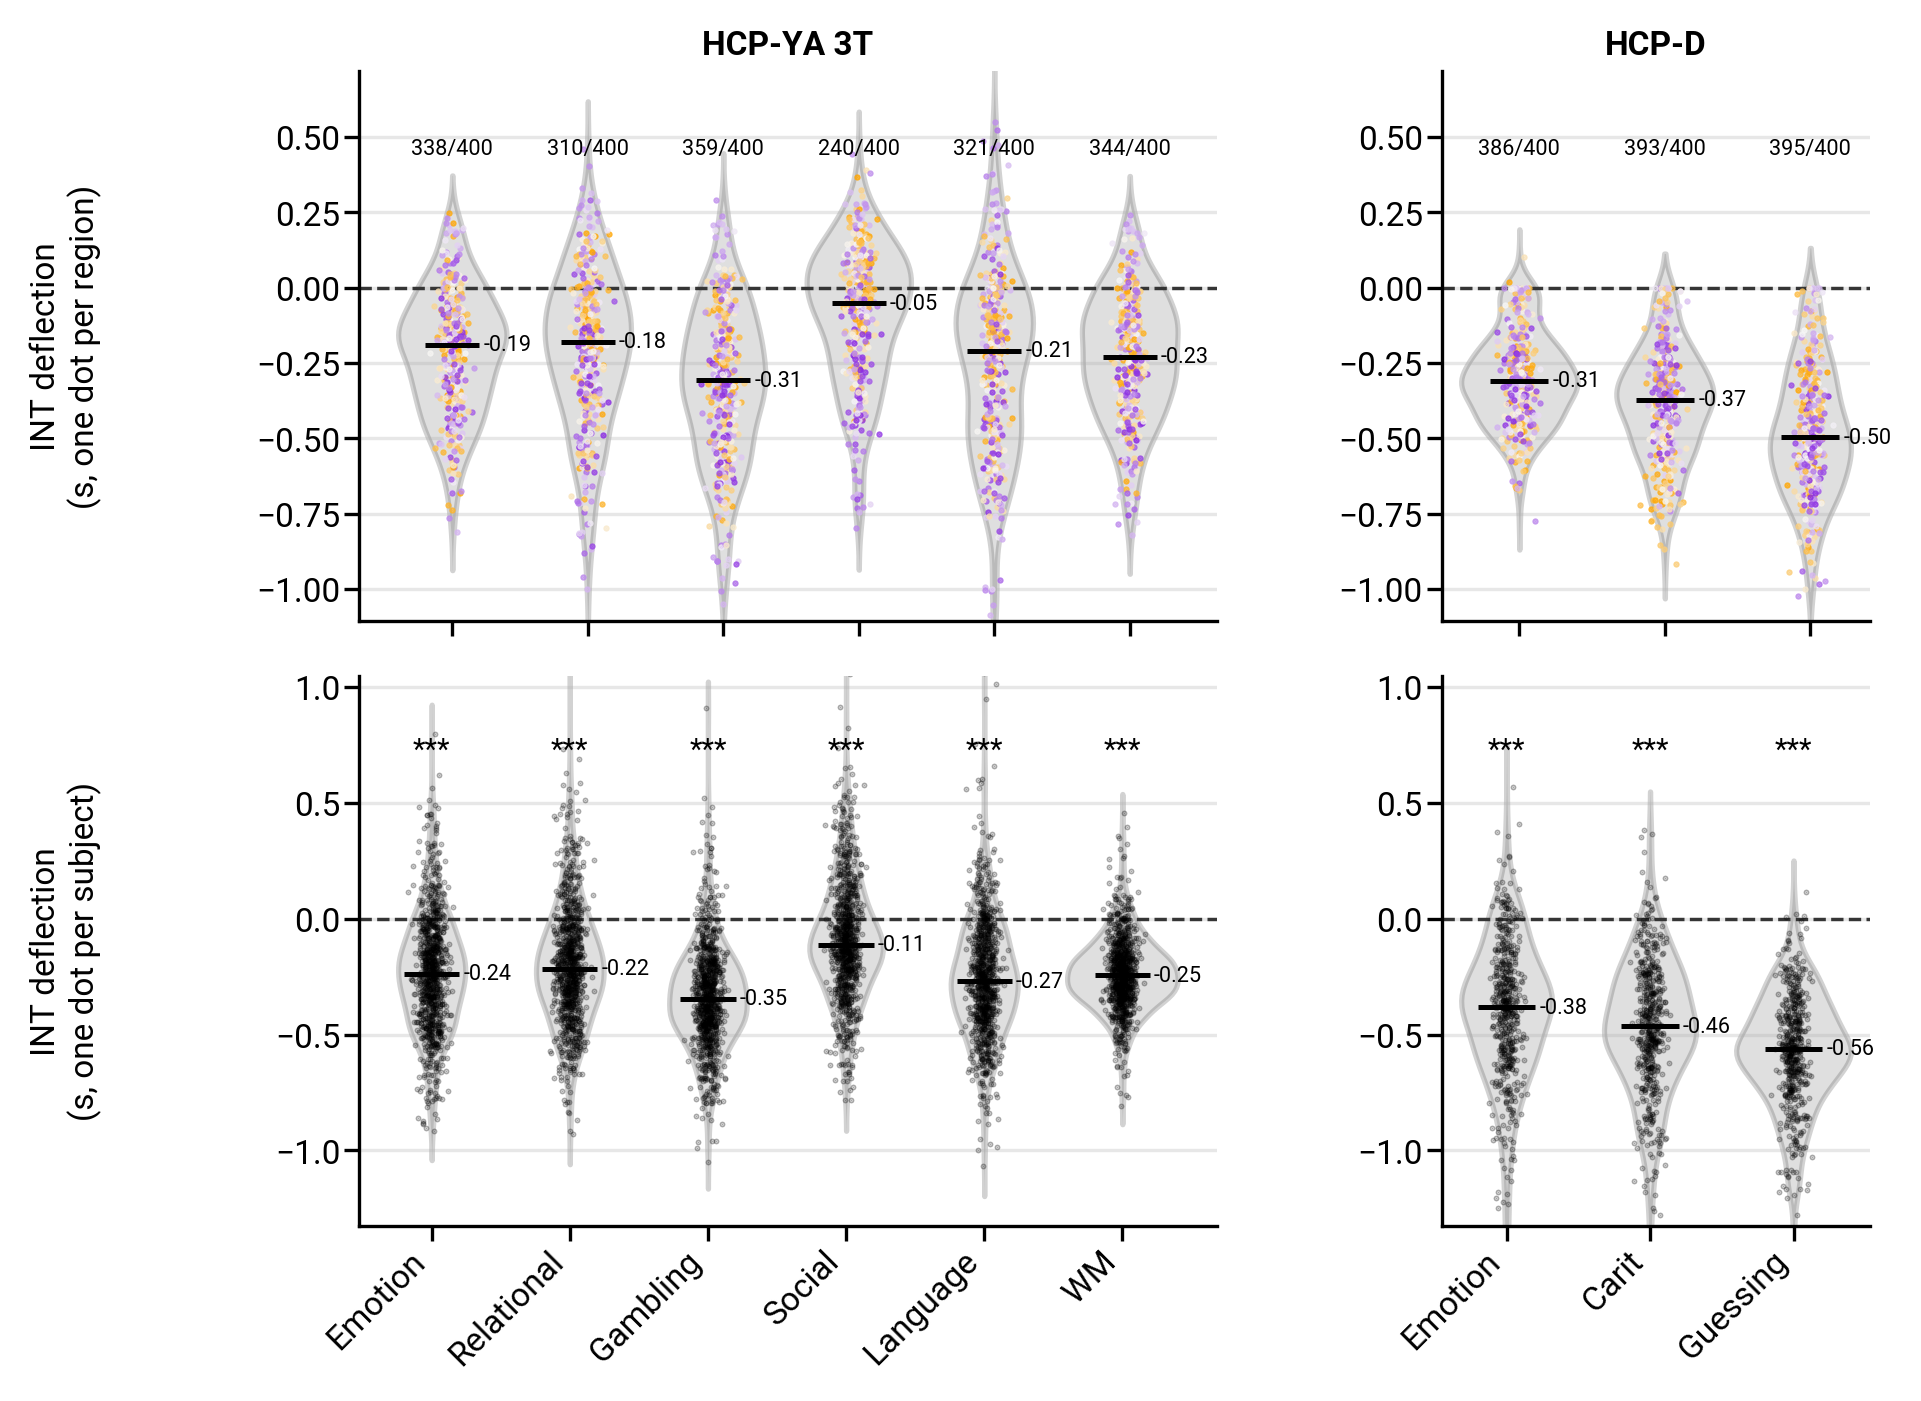

In [6]:
# Every quantity was computed above; this cell only draws.
rc_col_ids = [spec['id'] for spec in RC_BLOCKS]
rc_cells = {bid: sorted([c for c in rc_maps if c[0] == bid],
                         key=lambda c: RC_ORDER[bid].index(c[1])) for bid in rc_col_ids}
rc_widths = [len(rc_cells[bid]) for bid in rc_col_ids]

# One y-range per row, shared across columns, so the scale difference between datasets is
# visible rather than hidden by per-panel autoscaling.
rc_row_source = [rc_region_defl, rc_subject_defl]
rc_row_ylim = []
for source in rc_row_source:
    stacked = np.concatenate([np.asarray(source[c]).ravel() for c in rc_maps])
    lo, hi = np.nanpercentile(stacked, RC_YLIM_PCT)
    pad = 0.12 * (hi - lo)
    rc_row_ylim.append((min(lo - pad, -pad), hi + 2.6 * pad))

fig_alt = plt.figure(figsize=(6.5, 5.0), dpi=300)
gs_alt = gridspec.GridSpec(2, len(rc_col_ids), width_ratios=rc_widths,
                           hspace=0.10, wspace=0.35)

rc_row_names = ['regions', 'subjects']
for row, source in enumerate(rc_row_source):
    ylo, yhi = rc_row_ylim[row]
    for col, bid in enumerate(rc_col_ids):
        cells = rc_cells[bid]
        ax = fig_alt.add_subplot(gs_alt[row, col])
        df_col = pd.DataFrame({rc_meta[c]['label']: np.asarray(source[c]) for c in cells})

        # Regions carry the S-A colouring; subjects have no position on that axis.
        colour_kwargs = (dict(color_vector=rc_df_neuro[RC_BRAIN_MAP],
                              colormap='snap_sydnor_sa')
                         if row == 0 else dict(color_vector=None))
        ax = plot_repeated_measures_violins(
            df_col, ax, add_colorbar=False, point_alpha=0.85 if row == 0 else 0.35,
            line_alpha=RC_LINE_ALPHA[rc_row_names[row]],
            point_size=0.25 if row == 0 else 0.15,
            line_width=0.2, violin_alpha=0.25, correlation_method=None,
            annotate_variance=False, **colour_kwargs)
        ax.axhline(0, color='black', lw=0.8, ls='--', zorder=1)

        for j, cell in enumerate(cells):
            annot = rc_annot[(rc_meta[cell]['title'], rc_meta[cell]['label'])]
            values = np.asarray(source[cell])
            values = values[np.isfinite(values)]
            med = float(np.median(values))
            q25, q75 = np.percentile(values, [25, 75])
            # median + IQR, drawn from values computed above -- the helper draws inner=None
            # ax.vlines(j, q25, q75, color='black', lw=1.8, alpha=0.8, zorder=6)
            ax.hlines(med, j - 0.20, j + 0.20, color='black', lw=1.2, zorder=7)
            ax.text(j + 0.23, med, f'{med:+.2f}', fontsize=5.2, va='center', ha='left',
                    zorder=8)
            top = annot['count'] if row == 0 else annot['sig']
            ax.text(j, yhi - 0.16 * (yhi - ylo), top, ha='center', va='bottom',
                    fontsize=5.2 if row == 0 else 7)

        if RC_SHARE_Y:
            ax.set_ylim(ylo, yhi)
        if row == 0:
            ax.set_title(rc_meta[cells[0]]['title'], fontsize=8, fontweight='bold', pad=4)
            ax.set_xticklabels([])
        else:
            ax.tick_params(axis='x', rotation=45, pad=1)
            for label in ax.get_xticklabels():
                label.set_ha('right')
        ax.set_xlabel('')
        ax.tick_params(axis='y', which='major', pad=1)
        ax.set_ylabel(('INT deflection\n(s, one dot per region)' if row == 0 else
                       'INT deflection\n(s, one dot per subject)') if col == 0 else '',
                      fontsize=8)
        ax.yaxis.set_label_coords(-0.30, 0.5)

plt.tight_layout()
print(save_panel(fig_alt, figure_scratch_dir(), 'timescales_analysis_sfig_rest_regression',
                 transparent=False))
plt.show()